# Dong 2020 Prostate — 01 Preprocessing
Malignant compartment: load -> threshold -> overdispersed -> PCA -> Harmony(`sample`) -> UMAP -> Leiden -> cell-cycle scoping -> module/lineage biology -> annotate. Output suffix `-5`.

**Gate-1 lead (embedding, not scalar):** mixing + continuity are judged on the regenerated embedding across a Harmony-`theta` x `n_pcs` sweep with per-neighbourhood iLISI. **Scoping lead:** each lobe's biology (cell cycle + signatures) is settled *before* the GO and the proliferative compartment is excluded from the trajectory.

In [1]:
import os, sys
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from harmonypy import compute_lisi
from scipy.stats import pearsonr
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1; np.random.seed(1)

In [2]:
# custom 3CA dataloader; derive JoinKey base from the run dir name
pth_3ca, name = os.path.split(os.getcwd())        # name = 'Dong2020_Prostate-5'
base = name.rsplit('-', 1)[0]                      # 'Dong2020_Prostate'
sys.path.append('/home/caleb/MesenCoder/cancer/vertebrate/CCCA/scripts')
from load import load_CCCA_adata

In [3]:
# path logic - the <Category> partition sits one level deeper than the Puram anchor
pth      = os.path.join('..', '..', '..', '..', '..', '..')   # -> repo root
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', f'Data_{base}')
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Prostate', name)
pth_fig  = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Prostate', name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(os.path.join(pth_fig, 'colorbars'), exist_ok=True)
print('leaf in :', os.path.abspath(pth_in)); print('h5ad out:', os.path.abspath(pth_out))

leaf in : /home/caleb/MesenCoder/data/unzip/CCCA/Data_Dong2020_Prostate
h5ad out: /home/caleb/MesenCoder/data/cancer/vertebrate/CCCA/Claude/Prostate/Dong2020_Prostate-5


### Load malignant cells
Use **only** `Data_Dong2020_Prostate` (a separate `Data_Dong2020_Neuroendocrine` folder is a different dataset). The loader auto-detects normalization -> log1p and sets `celltype` default `'Malignant'`.

In [4]:
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape)
adata.obs['sample'].value_counts()

Loading ../../../../../../data/unzip/CCCA/Data_Dong2020_Prostate
Done.
malignant: (9698, 15709)


sample
patient #6    4765
patient #1    2345
patient #5    1673
patient #2     915
Name: count, dtype: int64

### Threshold under-populated samples (derived; C3 premise checked, not assumed)
Patients #3/#4 contribute **0** malignant cells. Among the 4 present samples the sorted counts are 4765 / 2345 / 1673 / 915, adjacent gap ratios 2.03 / 1.40 / 1.83 - **no dominant multiplicative cliff** (top/runner-up 1.11 < 1.5), so the 'clean count gap' premise is **not met**. All four sit far above 100 -> fall back to the anchor **>=100 floor**, keeping all four.

In [5]:
n = adata.obs['sample'].value_counts()
cnt = np.sort(n.values)[::-1]
print('sorted counts :', cnt)
print('gap ratios    :', np.round(cnt[:-1] / cnt[1:], 3))
keep = n.index[n >= 100]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('kept          :', list(keep), '| cells:', adata.n_obs)

sorted counts : [4765 2345 1673  915]
gap ratios    : [2.032 1.402 1.828]
kept          : ['patient #6', 'patient #1', 'patient #5', 'patient #2'] | cells: 9698


### Gene filter + overdispersed selection
No `sc.pp.scale` before PCA (absent from the reference protocol).

In [6]:
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata)
adata.raw = adata
print('overdispersed:', int(adata.var.highly_variable.sum()))

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1670 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed: 1670


### PCA -> Harmony integrate on `sample`

In [7]:
sc.pp.pca(adata, n_comps = 50, use_highly_variable = True)
sce.pp.harmony_integrate(adata, 'sample', theta = 10, max_iter_harmony = 30, random_state = 1)

### Gate 1 - integration sweep, judged on the EMBEDDING + per-neighbourhood iLISI
One patient (#6, small-cell-NEPC histology) is ~49% of malignant cells, which caps the global iLISI scalar; the call is therefore read on the **embedding** across `theta` (and confirmed `n_pcs`-invariant), not on the scalar. iLISI rises monotonically with integration strength and the compartment stays a single connected mass.

In [8]:
reps = {}
for th in [0, 2, 5, 10]:
    key = f'harm_th{th}'
    if th == 0: adata.obsm[key] = adata.obsm['X_pca'].copy()
    else: sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, adjusted_basis=key, random_state=1)
    reps[th] = key
rows = []
for th in [0,2,5,10]:
    for npc in [20,30,40]:
        lis = compute_lisi(adata.obsm[reps[th]][:,:npc], adata.obs[['sample']], ['sample'])[:,0]
        rows.append(dict(theta=th, n_pcs=npc, iLISI=float(np.median(lis))))
grid = pd.DataFrame(rows).pivot(index='theta', columns='n_pcs', values='iLISI').round(2)
print('median iLISI (max = 4 samples):'); print(grid)

median iLISI (max = 4 samples):
n_pcs    20    30    40
theta                  
0      1.00  1.00  1.00
2      1.00  1.00  1.00
5      1.07  1.05  1.05
10     1.28  1.23  1.19


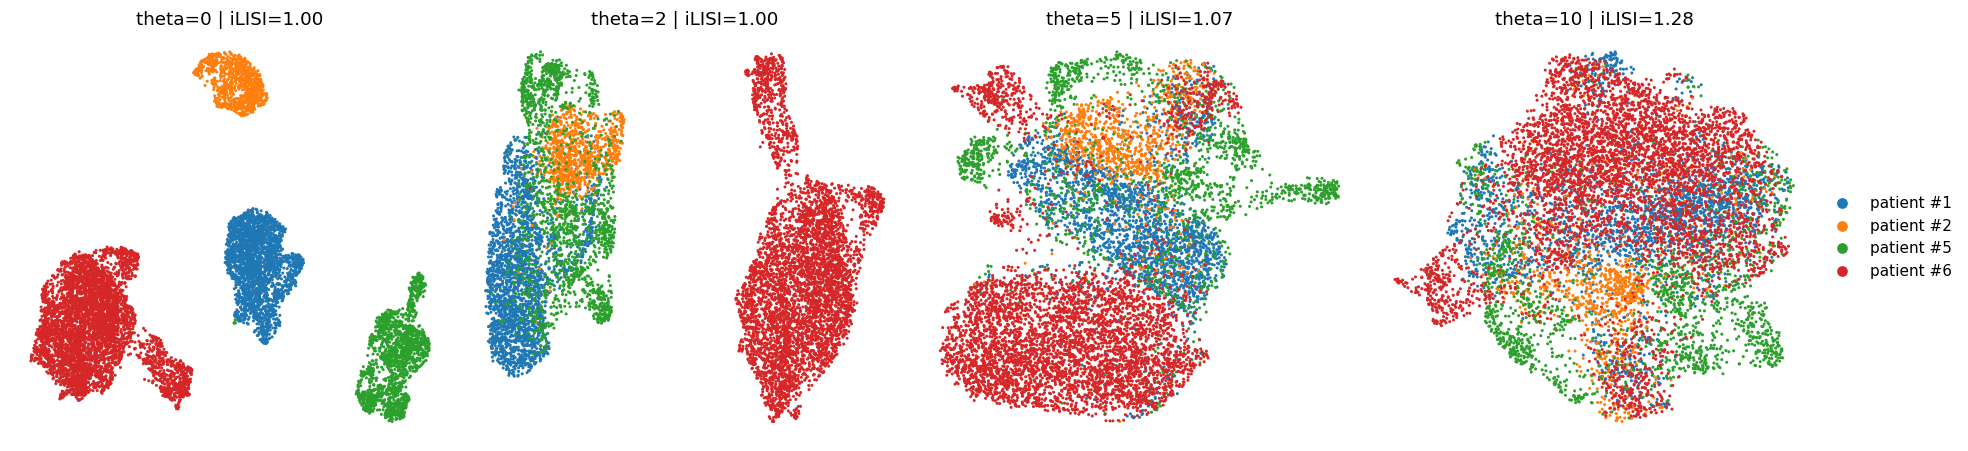

In [9]:
# sample mixing across the theta sweep - the Gate-1 embedding read
fig, axs = plt.subplots(1, 4, figsize=(18, 4.2))
for a, th in zip(axs, [0,2,5,10]):
    sc.pp.neighbors(adata, n_pcs=20, use_rep=reps[th], random_state=1)
    sc.tl.umap(adata, spread=1.3, random_state=1)
    sc.pl.umap(adata, color='sample', size=16, ax=a, show=False, frameon=False,
               title=f'theta={th} | iLISI={grid.loc[th,20]:.2f}', legend_loc='right margin' if th==10 else None)
plt.tight_layout(); plt.show()

In [10]:
# commit theta=10, n_pcs=20 embedding
sc.pp.neighbors(adata, n_pcs=20, n_neighbors=30, use_rep='X_pca_harmony', random_state=1)
sc.tl.umap(adata, spread=1.3, random_state=1)
ncomp, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN connected components:', ncomp, '(1 = single continuous manifold, no archipelago)')

kNN connected components: 1 (1 = single continuous manifold, no archipelago)


### Cell-cycle scoring -> isolate the proliferative compartment (SCOPING)
A cross-patient cycling compartment sits at the Gast/pSom-high end and **confounds the developmental origin**. This dataset's prior linear-GO attempts kept it and read a proliferation-inflated origin gradient. Score cycle, cluster, and split off high-cycling clusters (cycling fraction > 0.6, corroborated by MKI67/TOP2A/UBE2C/STMN1) *before* fitting any trajectory.

In [11]:
S = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
G2M = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
S = [g for g in S if g in adata.var_names]; G2M = [g for g in G2M if g in adata.var_names]
sc.tl.score_genes_cell_cycle(adata, s_genes=S, g2m_genes=G2M)
sc.tl.leiden(adata, resolution=0.5, random_state=1, flavor='igraph', n_iterations=2, directed=False)
cf = adata.obs.groupby('leiden', observed=True).apply(lambda d:(d.phase!='G1').mean())
mk = [g for g in ['MKI67','TOP2A','UBE2C','STMN1'] if g in adata.var_names]
pr = pd.DataFrame(adata[:,mk].X.toarray(), columns=mk, index=adata.obs_names).groupby(adata.obs.leiden.values).mean().mean(1)
prof = pd.DataFrame({'n':adata.obs.leiden.value_counts(),'cyc_frac':cf.round(2),'prolif_mean':pr.round(2)}).sort_index()
print(prof)
cyc = cf[cf > 0.6].index.tolist()
adata.obs['compartment'] = np.where(adata.obs.leiden.isin(cyc), 'Cycling', 'Developmental')
print('cycling clusters:', cyc, '|', adata.obs.compartment.value_counts().to_dict())

      n  cyc_frac  prolif_mean
0  1043      0.98         1.26
1  1463      0.32         0.34
2   374      0.93         0.95
3   312      0.18         0.25
4  1887      0.45         0.42
5  1663      0.23         0.24
6  1493      0.29         0.36
7  1463      0.24         0.38
cycling clusters: ['0', '2'] | {'Developmental': 8281, 'Cycling': 1417}


### Embryonic modules + prostate-lineage biology (settle lobe identity before the GO)
Modules scored with the **union control pool** (protocol). The prostate lineage axis (AR-luminal vs neuroendocrine) is mapped to show it is a continuous, **multi-patient** gradient that is **orthogonal** to the Gast/pSom module axis the gates test.

In [12]:
getf = lambda fn: pd.read_csv(os.path.join(pth_feat, fn)).hsapiens.drop_duplicates()
gref = list(getf('union.csv')[getf('union.csv').isin(adata.var_names)])
for key, fn in [('GSE162534','GSE162534.csv'),('GSE229103','GSE229103.csv'),('rRNAModifications','rRNAModifications.csv')]:
    g = list(getf(fn)[getf(fn).isin(adata.var_names)])
    sc.tl.score_genes(adata, g, score_name=key, ctrl_as_ref=False, gene_pool=gref, random_state=1234)
    print(key, len(g), 'genes | mean =', round(adata.obs[key].mean(), 4))
adata.obs['Gast']=adata.obs['GSE162534']; adata.obs['pSom']=adata.obs['GSE229103']; adata.obs['Crest']=adata.obs['rRNAModifications']

GSE162534 71 genes | mean = 0.035
GSE229103 83 genes | mean = 0.1004
rRNAModifications 99 genes | mean = -0.0406


In [13]:
AR = [g for g in ['AR','KLK3','KLK2','NKX3-1','FOLH1','TMPRSS2','ACPP','STEAP2'] if g in adata.var_names]
NE = [g for g in ['CHGA','CHGB','SYP','NCAM1','ASCL1','INSM1','SOX2','ENO2','ELAVL4','CALCA'] if g in adata.var_names]
sc.tl.score_genes(adata, AR, score_name='AR_luminal', random_state=1)
sc.tl.score_genes(adata, NE, score_name='NE_program', random_state=1)
print('AR markers:', AR); print('NE markers:', NE)

AR markers: ['AR', 'NKX3-1', 'FOLH1', 'TMPRSS2', 'ACPP', 'STEAP2']
NE markers: ['CHGA', 'CHGB', 'SYP', 'NCAM1', 'ASCL1', 'INSM1', 'SOX2', 'ENO2']


In [14]:
# PRELIMINARY diagnostic (cell-level Pearson on the full object): the (Gast,pSom)-vs-Crest
# anti-correlation survives within non-cycling cells -> the axis is developmental, not
# proliferative. NB these full-object values (Gast-pSom ~ +0.5) are a scoping cross-check;
# the CANONICAL Gate-2 module co-variation (Gast<->pSom = +0.47) is scored on the manifold
# in 03_signatures and is the value reported in summary.pdf and the log.
def mc(m):
    d = adata[m]
    return {f'{x}-{y}': round(pearsonr(d.obs[x], d.obs[y])[0], 2) for x,y in [('Gast','pSom'),('Gast','Crest'),('pSom','Crest')]}
print('ALL cells     :', mc(np.ones(adata.n_obs, bool)))
print('developmental :', mc((adata.obs.compartment=='Developmental').values))

ALL cells     : {'Gast-pSom': np.float64(0.57), 'Gast-Crest': np.float64(-0.44), 'pSom-Crest': np.float64(-0.45)}
developmental : {'Gast-pSom': np.float64(0.52), 'Gast-Crest': np.float64(-0.37), 'pSom-Crest': np.float64(-0.4)}


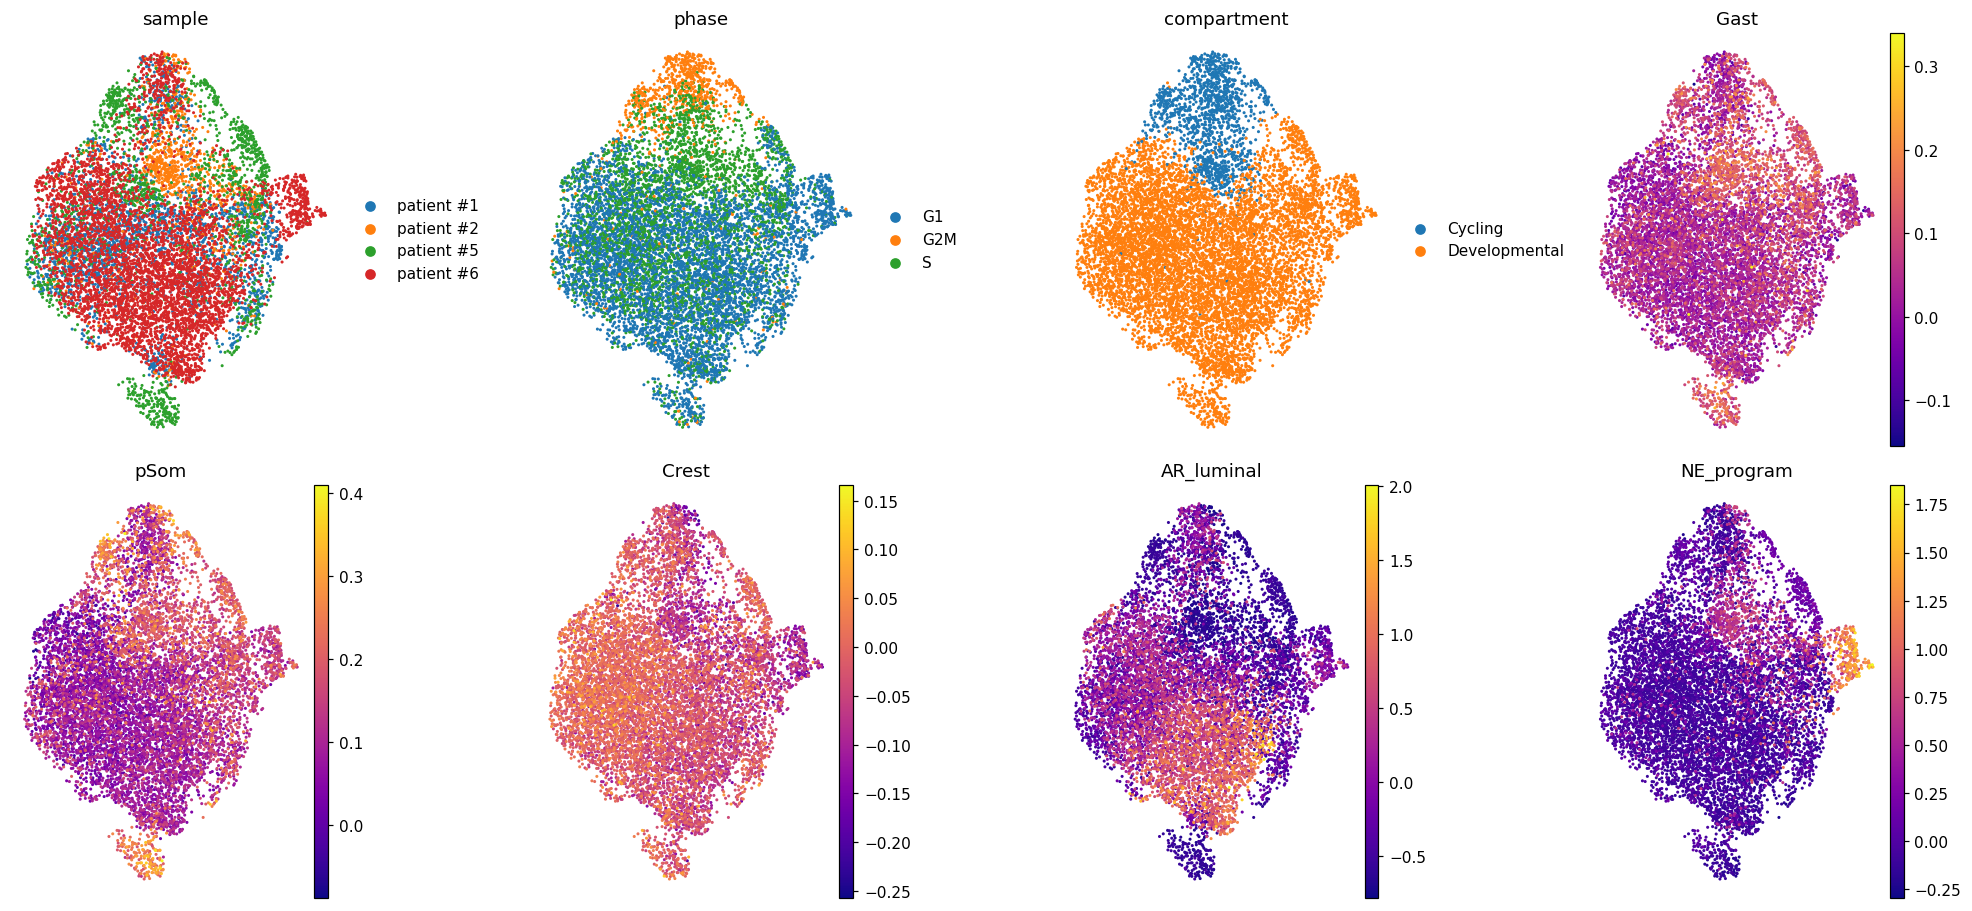

In [15]:
# biology geography (raw scores) on the committed embedding
fig, axs = plt.subplots(2, 4, figsize=(18, 8.4))
for a, c in zip(axs.flat, ['sample','phase','compartment','Gast','pSom','Crest','AR_luminal','NE_program']):
    sc.pl.umap(adata, color=c, size=16, ax=a, show=False, frameon=False,
               cmap='plasma' if c not in ('sample','phase','compartment') else None, title=c)
plt.tight_layout(); plt.show()

### Annotate poles (data-derived markers **and** publication)
Dong et al. 2020 (Cancer Cell) report 5 adenocarcinoma + 1 small-cell NEPC patient. At the **cell** level the lineage programs partly cross patients and do not map cleanly onto per-patient clinical histology; the malignant manifold is one continuous AR-luminal <-> neuroendocrine axis. Poles are labelled by AR-luminal vs NE marker score.

In [16]:
adata.obs['lineage'] = np.where(adata.obs.NE_program > adata.obs.AR_luminal, 'Neuroendocrine', 'AR-luminal')
print(pd.crosstab(adata.obs['sample'], adata.obs['lineage']))
adata.obs['celltype'] = pd.Categorical(adata.obs['lineage'])   # used by the reference overlay style downstream

lineage     AR-luminal  Neuroendocrine
sample                                
patient #1         251            2094
patient #2           0             915
patient #5           0            1673
patient #6        4048             717


### No detached islands to remove
The embedding is a single connected component (checked above), as is the developmental compartment used for the trajectory. Only the proliferative compartment is set aside (scoping); nothing is removed as a detached island.

In [17]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved', os.path.join(pth_out, 'processed.h5ad'), adata.shape)

saved ../../../../../../data/cancer/vertebrate/CCCA/Claude/Prostate/Dong2020_Prostate-5/processed.h5ad (9698, 15672)
